# Phase 5 — Model Training for FD001
**Project:** Intelligent Predictive Maintenance — RUL Estimation (NASA C-MAPSS)
**Notebook:** `04_Model_Training_FD001.ipynb`

This notebook trains the **four core algorithms** on FD001 using the preprocessing (Phase 3) and features (Phase 4) we already froze:

| # | Model | Input | Tuned? |
|---|---|---|---|
| 1 | Linear Regression | 57 tabular features | No hyperparameters (baseline) |
| 2 | Random Forest | 57 tabular features | Small grid (8 configs) |
| 3 | XGBoost | 57 tabular features | Small grid (6 configs) + early stopping |
| 4 | LSTM | 30 cycles × 14 sensors | 4 architectures + early stopping |

### Validation protocol — identical for all 4 models (fair comparison)
```
100 training engines ──┬── 80 TRAIN engines ──┬── 64 "fit" engines   → fit candidate configs
                       │                       └── 16 "tune" engines  → choose hyperparameters (160 cut points)
                       │                         then: re-train chosen config on all 80 engines
                       └── 20 VALIDATION engines → final comparison only (200 cut points, from Phase 3)
Official NASA test set → NOT used in this phase (reserved for Phase 6, once, after selection)
```
**Why an inner "tune" split?** If we tuned hyperparameters on the 200 validation points *and* reported scores on the same points, the scores would be optimistically biased (we'd be picking whatever happens to fit those 20 engines). Tuning on 16 separate engines keeps the 20 validation engines an honest final check.

**Metric used everywhere:** RMSE on test-like cut points with **true RUL ≤ 125** (primary), plus MAE, NASA score, bias (+ = late = dangerous) and RMSE over all points. Error convention: `d = predicted − true`.


## Cell 1 — Setup: Drive, paths, device, seed
Works in Colab (mounts Drive) and also locally (set `CMAPSS_RAW_DIR` and `PROJECT_DIR` environment variables).

In [1]:
# Cell 1 — Setup
import os, sys, json, time, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from google.colab import drive
    drive.mount('/content/drive')
    RAW_DIR     = Path("/content/drive/MyDrive/CMAPSSData")
    PROJECT_DIR = Path("/content/drive/MyDrive/Predictive_Maintenance_RUL")
except ImportError:                                   # running locally
    RAW_DIR     = Path(os.environ["CMAPSS_RAW_DIR"])
    PROJECT_DIR = Path(os.environ["PROJECT_DIR"])

FD, SEED = "FD001", 42
SRC_DIR    = PROJECT_DIR / "src"
MODEL_DIR  = PROJECT_DIR / "models" / FD
PREP_DIR   = MODEL_DIR / "preprocessing"
PROC_DIR   = PROJECT_DIR / "data" / "processed" / FD
FIG_DIR    = PROJECT_DIR / "reports" / "figures" / FD
RESULT_DIR = PROJECT_DIR / "reports" / "model_results" / FD
for p in (FIG_DIR, RESULT_DIR):
    p.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_DIR))
sns.set_theme(style="whitegrid")

import torch, xgboost, sklearn
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"torch {torch.__version__} | xgboost {xgboost.__version__} | scikit-learn {sklearn.__version__}")
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU only (slower LSTM)")
print("CPU cores:", os.cpu_count())
assert int(xgboost.__version__.split(".")[0]) >= 2, "Need xgboost >= 2.0: run  !pip install -U xgboost"

# Phase 4 must have been completed
assert (MODEL_DIR / "feature_config.json").exists(), "feature_config.json missing → finish Phase 4 (03b, Cell 8) first"
assert (PREP_DIR / "scaler.joblib").exists(), "Preprocessing pipeline missing → finish Phase 3 (03, Cell 13) first"
print("✅ Phase 3 + Phase 4 artifacts found")

Mounted at /content/drive
torch 2.14.1+cu130 | xgboost 3.4.1 | scikit-learn 1.6.1
Device: cuda | Tesla T4
CPU cores: 2
✅ Phase 3 + Phase 4 artifacts found


## Cell 2 — Write `src/model_training.py`
**Why this file exists:** FD002–FD004 will train the same 4 algorithms. All the reusable logic lives here (tuning loop, LSTM architecture, early-stopping training loop, timing, saving), so each dataset notebook just calls functions. The FastAPI backend will later import `build_lstm` / `load_lstm` from this file to rebuild the LSTM from disk.

Key pieces:
| Function | Purpose |
|---|---|
| `point_metrics` | Metrics on cut points vs **true (uncapped)** RUL; primary = RMSE where true RUL ≤ cap |
| `tune_tabular` | Fit each candidate config on 64 fit-engines, score on the 16 tune-engines |
| `build_lstm` | LSTM → takes the **last time step's** hidden state → small dense head → RUL/125 |
| `train_lstm` | Mini-batch training, MSE loss, gradient clipping, **early stopping** with best-weight restore |
| `time_inference` | Median of 5 timed prediction runs |
| `save_model_bundle` | Saves model file + `metadata.json` that points to its preprocessing + feature config |

In [2]:
%%writefile {SRC_DIR}/model_training.py
"""
model_training.py â€” Training, tuning, timing and saving for the 4 core RUL models.

Why this file exists: FD001-FD004 all use the same 4 algorithms (Linear Regression,
Random Forest, XGBoost, LSTM). Keeping the training logic here means each dataset
notebook only calls functions, and the FastAPI backend can re-use the LSTM class and
the loaders to rebuild exactly the same models from disk.

Validation protocol (identical for all 4 models):
  * 80 training engines  -> inner split: 64 "fit" engines + 16 "tune" engines
  * hyperparameters are chosen on the 16 tune engines (test-like cut points)
  * the chosen configuration is re-trained on all 80 training engines
  * the 20 validation engines (200 cut points) are used ONLY for the final comparison
  * the official NASA test set is NOT touched in this phase
"""
import json
import random
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

from src import evaluation as ev


# ----------------------------------------------------------------------------- reproducibility
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass


# ----------------------------------------------------------------------------- metrics
def point_metrics(y_true, y_pred, cap: float) -> dict:
    """Metrics on test-like cut points, against the TRUE (uncapped) RUL.
    Primary selection metric: RMSE on points with true RUL <= cap (maintenance-relevant zone)."""
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    m = y_true <= cap
    return {
        "RMSE_le_cap": ev.rmse(y_true[m], y_pred[m]),
        "MAE_le_cap": ev.mae(y_true[m], y_pred[m]),
        "NASA_le_cap": ev.nasa_score(y_true[m], y_pred[m]),
        "bias_le_cap": float(np.mean(y_pred[m] - y_true[m])),
        "RMSE_all": ev.rmse(y_true, y_pred),
        "MAE_all": ev.mae(y_true, y_pred),
        "n_points": int(len(y_true)),
        "n_points_le_cap": int(m.sum()),
    }


def time_inference(predict_fn, n_repeats: int = 5):
    """Run predict_fn several times; return (predictions, median seconds)."""
    times, pred = [], None
    for _ in range(n_repeats):
        t0 = time.perf_counter()
        pred = predict_fn()
        times.append(time.perf_counter() - t0)
    return pred, float(np.median(times))


# ----------------------------------------------------------------------------- tabular models
def tune_tabular(make_model, param_grid, X_fit, y_fit, X_tune, y_tune_true, cap, fit_kwargs_fn=None,
                 verbose=True):
    """Try every config in `param_grid` (list of dicts): fit on fit-engines, score on tune cut points.
    Returns (results DataFrame sorted best-first, best params dict, best fitted model)."""
    rows, best = [], (np.inf, None, None)
    for i, params in enumerate(param_grid, 1):
        model = make_model(**params)
        t0 = time.perf_counter()
        kwargs = fit_kwargs_fn(model) if fit_kwargs_fn else {}
        model.fit(X_fit, y_fit, **kwargs)
        fit_s = time.perf_counter() - t0
        pred = np.clip(model.predict(X_tune), 0, None)
        m = point_metrics(y_tune_true, pred, cap)
        extra = {}
        if hasattr(model, "best_iteration") and getattr(model, "best_iteration", None) is not None:
            extra["best_iteration"] = int(model.best_iteration)
        rows.append({**params, **extra, "tune_RMSE_le_cap": m["RMSE_le_cap"],
                     "tune_NASA_le_cap": m["NASA_le_cap"], "fit_s": fit_s})
        if verbose:
            print(f"  [{i}/{len(param_grid)}] {params} {extra} -> tune RMSE<=cap {m['RMSE_le_cap']:.2f} "
                  f"({fit_s:.1f}s)")
        if m["RMSE_le_cap"] < best[0]:
            best = (m["RMSE_le_cap"], {**params, **extra}, model)
    res = pd.DataFrame(rows).sort_values("tune_RMSE_le_cap").reset_index(drop=True)
    return res, best[1], best[2]


# ----------------------------------------------------------------------------- LSTM
def _torch():
    import torch
    import torch.nn as nn
    return torch, nn


def build_lstm(n_features: int, hidden: int = 64, layers: int = 1, dropout: float = 0.0):
    """LSTM regressor: sequence [batch, seq_len, n_features] -> RUL / cap (scalar)."""
    torch, nn = _torch()

    class LSTMRegressor(nn.Module):
        def __init__(self):
            super().__init__()
            self.lstm = nn.LSTM(n_features, hidden, num_layers=layers, batch_first=True,
                                dropout=dropout if layers > 1 else 0.0)
            self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Linear(32, 1))

        def forward(self, x):
            out, _ = self.lstm(x)              # out: [batch, seq_len, hidden]
            return self.head(out[:, -1]).squeeze(-1)   # use the LAST time step's summary

    return LSTMRegressor()


def lstm_predict(model, X, cap: float, device: str = "cpu", batch_size: int = 2048):
    torch, _ = _torch()
    model.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            xb = torch.as_tensor(X[i:i + batch_size], dtype=torch.float32, device=device)
            preds.append(model(xb).float().cpu().numpy())
    return np.clip(np.concatenate(preds) * cap, 0, None)


def train_lstm(config: dict, X_train, y_train, cap: float, X_val=None, y_val=None, epochs: int = 50,
               patience: int = 8, lr: float = 1e-3, batch_size: int = 256, device: str = "cpu",
               seed: int = 42, verbose=True):
    """Train with MSE loss on RUL/cap (targets scaled to ~[0,1] for stable training).
    If validation windows are given: early stopping on validation loss, best weights restored.
    Returns (model, history DataFrame, best_epoch)."""
    torch, nn = _torch()
    set_seed(seed)
    model = build_lstm(X_train.shape[2], **config).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    Xt = torch.as_tensor(X_train, dtype=torch.float32)
    yt = torch.as_tensor(y_train / cap, dtype=torch.float32)
    gen = torch.Generator().manual_seed(seed)
    history, best_loss, best_state, best_epoch, bad = [], np.inf, None, 0, 0
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(Xt), generator=gen)
        total = 0.0
        for i in range(0, len(Xt), batch_size):
            idx = perm[i:i + batch_size]
            xb, yb = Xt[idx].to(device), yt[idx].to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            total += loss.item() * len(idx)
        row = {"epoch": epoch, "train_loss": total / len(Xt)}
        if X_val is not None:
            pv = lstm_predict(model, X_val, cap, device) / cap
            row["val_loss"] = float(np.mean((pv - y_val / cap) ** 2))
            if row["val_loss"] < best_loss - 1e-5:
                best_loss, best_epoch, bad = row["val_loss"], epoch, 0
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
        history.append(row)
        if verbose and (epoch == 1 or epoch % 5 == 0):
            msg = f"    epoch {epoch:3d}  train {row['train_loss']:.4f}"
            if "val_loss" in row:
                msg += f"  val {row['val_loss']:.4f}  (best epoch {best_epoch})"
            print(msg)
        if X_val is not None and bad >= patience:
            if verbose:
                print(f"    early stop at epoch {epoch}; best epoch {best_epoch}")
            break
    if best_state is not None:
        model.load_state_dict(best_state)
    else:
        best_epoch = len(history)
    return model, pd.DataFrame(history), best_epoch


# ----------------------------------------------------------------------------- saving
def save_model_bundle(directory, model, kind: str, metadata: dict):
    """Save a trained model + metadata.json. kind: 'sklearn' | 'xgboost' | 'lstm'."""
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    if kind == "sklearn":
        joblib.dump(model, directory / "model.joblib", compress=3)
        metadata["model_file"] = "model.joblib"
    elif kind == "xgboost":
        model.save_model(directory / "model.json")
        metadata["model_file"] = "model.json"
    elif kind == "lstm":
        torch, _ = _torch()
        torch.save(model.state_dict(), directory / "model.pt")
        metadata["model_file"] = "model.pt"
    else:
        raise ValueError(kind)
    metadata["preprocessing_dir"] = "../preprocessing"
    metadata["feature_config"] = "../feature_config.json"
    (directory / "metadata.json").write_text(json.dumps(metadata, indent=2, default=float))
    size_mb = sum(p.stat().st_size for p in directory.iterdir()) / 1e6
    return size_mb


def load_lstm(directory, device: str = "cpu"):
    torch, _ = _torch()
    directory = Path(directory)
    meta = json.loads((directory / "metadata.json").read_text())
    model = build_lstm(meta["n_features"], **meta["architecture"])
    model.load_state_dict(torch.load(directory / "model.pt", map_location=device))
    return model.to(device).eval(), meta

Writing /content/drive/MyDrive/Predictive_Maintenance_RUL/src/model_training.py


## Cell 3 — Load frozen artifacts and build all model inputs
Nothing is re-fitted here: the scaler, feature list, cap, window and sequence length all come from Phase 3–4 files on Drive.

Note (honest detail): the saved scaler was fitted on all 80 training engines, which include the 16 tune engines. That only shares feature means/stds *within* the training engines — validation and test engines are untouched — and LR / RF / XGBoost are unaffected by scaling anyway.

In [3]:
# Cell 3 — Load artifacts + build datasets
import src.data_loader as dl, src.preprocessing as pp, src.evaluation as ev
import src.feature_engineering as fe, src.model_training as mt
for m in (dl, pp, ev, fe, mt):
    importlib.reload(m)
mt.set_seed(SEED)

feat_cfg = json.loads((MODEL_DIR / "feature_config.json").read_text())
pipe_meta = json.loads((PREP_DIR / "pipeline_metadata.json").read_text())
split = json.loads((PROC_DIR / "split.json").read_text())
val_cuts = pd.read_csv(PROC_DIR / "val_cut_points.csv")
prep = pp.CMAPSSPreprocessor.load(PREP_DIR)

CAP     = pipe_meta["rul_cap"]
B       = feat_cfg["base_features"]
WINDOW  = feat_cfg["tabular"]["window"]
INC_CYC = feat_cfg["tabular"]["include_cycle"]
NAMES   = feat_cfg["tabular"]["feature_order"]
SEQ_LEN = feat_cfg["lstm"]["seq_len"]
assert NAMES == fe.tabular_feature_names(B, WINDOW, INC_CYC) and B == prep.feature_cols

# Labels: capped target for training, true (uncapped) RUL for evaluation
d = dl.load_dataset(FD, RAW_DIR)
capped   = pp.add_train_rul(d["train"], cap=CAP)
uncapped = pp.add_train_rul(d["train"])

train_ids, val_ids = split["train_engine_ids"], split["val_engine_ids"]
fit_ids, tune_ids = pp.split_engines(capped[capped.engine_id.isin(train_ids)], val_fraction=0.2, seed=SEED)
tune_cuts = pp.make_eval_cut_points(uncapped[uncapped.engine_id.isin(tune_ids)], n_cuts=10, min_history=30, seed=SEED)
assert not set(fit_ids) & set(tune_ids) and set(fit_ids) | set(tune_ids) == set(train_ids)
assert not set(train_ids) & set(val_ids)

# Scale + tabular features (rolling features are per-engine and causal)
all_s = prep.transform(capped)
feat_all, _ = fe.build_tabular(all_s, B, WINDOW, INC_CYC)
sel = lambda ids: feat_all[feat_all.engine_id.isin(ids)]
X_fit, y_fit   = sel(fit_ids)[NAMES],   sel(fit_ids)["RUL"]
X_tr80, y_tr80 = sel(train_ids)[NAMES], sel(train_ids)["RUL"]
X_tune_rows, y_tune_rows = sel(tune_ids)[NAMES], sel(tune_ids)["RUL"]       # for XGBoost early stopping
X_tune_pts = fe.rows_at(feat_all, tune_cuts)[NAMES]; y_tune_true = tune_cuts["true_rul"].values
X_val_pts  = fe.rows_at(feat_all, val_cuts)[NAMES];  y_val_true  = val_cuts["true_rul"].values

# LSTM sequences (windows never cross engines)
seq = lambda ids: fe.make_sequences(all_s[all_s.engine_id.isin(ids)], B, SEQ_LEN)
S_fit, s_fit, _   = seq(fit_ids)
S_tune, s_tune, _ = seq(tune_ids)
S_tr80, s_tr80, _ = seq(train_ids)
S_tune_pts = fe.sequences_at(all_s, B, SEQ_LEN, tune_cuts)
S_val_pts  = fe.sequences_at(all_s, B, SEQ_LEN, val_cuts)

print(f"Cap {CAP} | {len(NAMES)} tabular features | LSTM {SEQ_LEN}×{len(B)}")
print(f"Engines: fit {len(fit_ids)} | tune {len(tune_ids)} | train(total) {len(train_ids)} | validation {len(val_ids)}")
print(f"Tabular rows: fit {len(X_fit)} | train80 {len(X_tr80)} | tune points {len(X_tune_pts)} | val points {len(X_val_pts)}")
print(f"LSTM windows: fit {S_fit.shape} | tune {S_tune.shape} | train80 {S_tr80.shape} | val points {S_val_pts.shape}")

results, val_preds = {}, {"engine_id": val_cuts.engine_id, "cut_cycle": val_cuts.cut_cycle, "true_rul": y_val_true}

Cap 125 | 57 tabular features | LSTM 30×14
Engines: fit 64 | tune 16 | train(total) 80 | validation 20
Tabular rows: fit 13114 | train80 16390 | tune points 160 | val points 200
LSTM windows: fit (11258, 30, 14) | tune (2812, 30, 14) | train80 (14070, 30, 14) | val points (200, 30, 14)


**Expected output:** `Cap 125 | 57 tabular features | LSTM 30×14`; engines fit 64 / tune 16 / train 80 / validation 20; tune points 160, val points 200; LSTM train80 windows `(14070, 30, 14)`.

---
## Cell 4 — Model 1: Linear Regression (baseline)
**What it is:** predicts RUL as a weighted sum of the 57 features: `RUL ≈ w₁·x₁ + … + w₅₇·x₅₇ + b`. It has no hyperparameters, so there's nothing to tune — we fit it directly on all 80 training engines.

**Why include it:** it's the baseline. Every other model must beat it to justify its extra complexity. Because the features are standardised, the size of each weight is roughly comparable, which gives a simple "importance" view.

**Post-processing (all models):** predictions are clipped at 0 because RUL can't be negative.

In [4]:
# Cell 4 — Linear Regression
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
t0 = time.perf_counter(); lr.fit(X_tr80, y_tr80); lr_train_s = time.perf_counter() - t0
pred, lr_inf_s = mt.time_inference(lambda: np.clip(lr.predict(X_val_pts), 0, None))
val_preds["Linear Regression"] = pred
results["Linear Regression"] = {**mt.point_metrics(y_val_true, pred, CAP),
                                "train_s": lr_train_s, "tuning_s": 0.0, "infer_ms_200": lr_inf_s * 1000}

coef = pd.Series(lr.coef_, index=NAMES)
top = coef.reindex(coef.abs().sort_values(ascending=False).index)[:12]
print("Largest |coefficients| (standardised features):"); print(top.round(2).to_string())

size = mt.save_model_bundle(MODEL_DIR / "linear_regression", lr, "sklearn", {
    "dataset": FD, "model": "Linear Regression", "input": "tabular", "feature_order": NAMES,
    "rul_cap": CAP, "hyperparameters": {}, "train_engines": len(train_ids),
    "train_time_s": lr_train_s, "validation_metrics": results["Linear Regression"]})
r = results["Linear Regression"]
print(f"\nValidation (200 pts): RMSE≤125 {r['RMSE_le_cap']:.2f} | MAE≤125 {r['MAE_le_cap']:.2f} | "
      f"bias {r['bias_le_cap']:+.1f} | RMSE all {r['RMSE_all']:.2f} | saved {size:.2f} MB")

Largest |coefficients| (standardised features):
sensor_14_slope_30    30.08
sensor_9_std_30      -25.85
sensor_12_std_30     -22.31
sensor_11_slope_30   -22.23
sensor_11_std_30     -18.79
sensor_14_mean_30    -17.51
sensor_9_mean_30      16.74
sensor_12_slope_30    14.39
sensor_13_mean_30     13.63
sensor_13_std_30     -13.45
sensor_13_slope_30   -13.24
sensor_2_slope_30    -13.03

Validation (200 pts): RMSE≤125 20.26 | MAE≤125 16.62 | bias +6.4 | RMSE all 41.86 | saved 0.00 MB


**How to read the coefficients:** a large positive weight pushes the RUL prediction up, a large negative weight pushes it down. Be careful: many features are strongly correlated (e.g. `sensor_9`/`sensor_14`, and each sensor with its own rolling mean), so individual weights can be large with opposite signs that partly cancel — that's multicollinearity, and why LR coefficients are not a reliable importance measure. We'll use SHAP later for proper explanations.

---
## Cell 5 — Model 2: Random Forest (tuned)
**What it is:** an average of many decision trees, each trained on a random resample of rows and considering a random subset of features at each split. Averaging many noisy trees reduces variance.

**Hyperparameters tuned (8 combinations, 150 trees each):**
| Parameter | Values | What it controls |
|---|---|---|
| `min_samples_leaf` | 3, 8 | Minimum rows in a leaf → larger = smoother, less overfitting |
| `max_features` | 0.33, 0.6 | Fraction of features tried per split → smaller = more diverse trees, faster |
| `max_depth` | None, 12 | Maximum tree depth → limits complexity |

**Why so small a search:** Random Forest runs on CPU only, and free Colab has ~2 cores. A small, sensible grid (~4–6 min) is enough to find a good region; huge random searches mostly fit noise in 16 tune engines. Progress prints after every fit.

In [5]:
# Cell 5 — Random Forest: tune on fit/tune engines, refit best on all 80
from sklearn.ensemble import RandomForestRegressor
from itertools import product

rf_grid = [{"min_samples_leaf": l, "max_features": f, "max_depth": dpt}
           for l, f, dpt in product([3, 8], [0.33, 0.6], [None, 12])]
make_rf = lambda **p: RandomForestRegressor(n_estimators=150, n_jobs=-1, random_state=SEED, **p)

t0 = time.perf_counter()
rf_tuning, rf_best, _ = mt.tune_tabular(make_rf, rf_grid, X_fit, y_fit, X_tune_pts, y_tune_true, CAP)
rf_tuning_s = time.perf_counter() - t0
rf_tuning.to_csv(RESULT_DIR / "rf_tuning.csv", index=False)
display(rf_tuning.round(3))
print("Best RF config:", rf_best)

rf = make_rf(**rf_best)
t0 = time.perf_counter(); rf.fit(X_tr80, y_tr80); rf_train_s = time.perf_counter() - t0
pred, rf_inf_s = mt.time_inference(lambda: np.clip(rf.predict(X_val_pts), 0, None))
val_preds["Random Forest"] = pred
results["Random Forest"] = {**mt.point_metrics(y_val_true, pred, CAP),
                            "train_s": rf_train_s, "tuning_s": rf_tuning_s, "infer_ms_200": rf_inf_s * 1000}

rf_imp = pd.Series(rf.feature_importances_, index=NAMES).sort_values(ascending=False)
rf_imp.to_csv(RESULT_DIR / "rf_feature_importance.csv")
size = mt.save_model_bundle(MODEL_DIR / "random_forest", rf, "sklearn", {
    "dataset": FD, "model": "Random Forest", "input": "tabular", "feature_order": NAMES, "rul_cap": CAP,
    "hyperparameters": {"n_estimators": 150, **rf_best}, "train_engines": len(train_ids),
    "train_time_s": rf_train_s, "tuning_time_s": rf_tuning_s, "validation_metrics": results["Random Forest"]})
r = results["Random Forest"]
print(f"Validation (200 pts): RMSE≤125 {r['RMSE_le_cap']:.2f} | MAE≤125 {r['MAE_le_cap']:.2f} | "
      f"bias {r['bias_le_cap']:+.1f} | RMSE all {r['RMSE_all']:.2f} | saved {size:.1f} MB")

  [1/8] {'min_samples_leaf': 3, 'max_features': 0.33, 'max_depth': None} {} -> tune RMSE<=cap 13.89 (25.1s)
  [2/8] {'min_samples_leaf': 3, 'max_features': 0.33, 'max_depth': 12} {} -> tune RMSE<=cap 14.30 (23.5s)
  [3/8] {'min_samples_leaf': 3, 'max_features': 0.6, 'max_depth': None} {} -> tune RMSE<=cap 14.30 (48.4s)
  [4/8] {'min_samples_leaf': 3, 'max_features': 0.6, 'max_depth': 12} {} -> tune RMSE<=cap 14.72 (42.9s)
  [5/8] {'min_samples_leaf': 8, 'max_features': 0.33, 'max_depth': None} {} -> tune RMSE<=cap 13.96 (23.1s)
  [6/8] {'min_samples_leaf': 8, 'max_features': 0.33, 'max_depth': 12} {} -> tune RMSE<=cap 14.07 (20.1s)
  [7/8] {'min_samples_leaf': 8, 'max_features': 0.6, 'max_depth': None} {} -> tune RMSE<=cap 14.36 (42.3s)
  [8/8] {'min_samples_leaf': 8, 'max_features': 0.6, 'max_depth': 12} {} -> tune RMSE<=cap 14.54 (39.4s)


,min_samples_leaf,max_features,max_depth,tune_RMSE_le_cap,tune_NASA_le_cap,fit_s
0,3,0.33,NaN,13.895,422.045,25.096
1,8,0.33,NaN,13.964,426.703,23.149
2,8,0.33,12.0,14.073,424.966,20.088
3,3,0.60,NaN,14.297,487.781,48.360
4,3,0.33,12.0,14.304,456.005,23.502
5,8,0.60,NaN,14.364,488.715,42.266
6,8,0.60,12.0,14.538,524.532,39.441
7,3,0.60,12.0,14.721,521.863,42.925


Best RF config: {'min_samples_leaf': 3, 'max_features': 0.33, 'max_depth': None}
Validation (200 pts): RMSE≤125 13.99 | MAE≤125 10.87 | bias +4.3 | RMSE all 37.83 | saved 11.6 MB


**Feature importance (impurity-based):** how much each feature reduced prediction error across all tree splits. It's quick but has known biases (it favours continuous, high-cardinality features and splits credit among correlated features), so treat it as a rough guide — SHAP in a later phase gives a more reliable picture.

---
## Cell 6 — Model 3: XGBoost (tuned, with early stopping)
**What it is:** *gradient boosting* — trees are built **one after another**, each new tree correcting the remaining errors of the previous ones. Random Forest averages independent trees (reduces variance); boosting adds corrective trees (reduces bias).

**Hyperparameters tuned (6 combinations):** `max_depth` ∈ {3, 5, 7} × `learning_rate` ∈ {0.03, 0.1}. Fixed: `subsample=0.8`, `colsample_bytree=0.8`, `min_child_weight=5`.

**Early stopping:** instead of guessing the number of trees, we allow up to 2000 and stop when the error on the 16 tune engines hasn't improved for 100 rounds. The best tree count is then reused when re-training on all 80 engines (no early stopping there, because there's no held-out data left inside the 80).

Runs on the GPU if available (`device="cuda"`).

In [6]:
# Cell 6 — XGBoost
from xgboost import XGBRegressor

xgb_grid = [{"max_depth": dp, "learning_rate": lr_} for dp, lr_ in product([3, 5, 7], [0.03, 0.1])]
xgb_common = dict(subsample=0.8, colsample_bytree=0.8, min_child_weight=5, tree_method="hist",
                  device=DEVICE, random_state=SEED, n_jobs=-1)
make_xgb = lambda **p: XGBRegressor(n_estimators=2000, early_stopping_rounds=100, eval_metric="rmse",
                                    **xgb_common, **p)

t0 = time.perf_counter()
xgb_tuning, xgb_best, _ = mt.tune_tabular(make_xgb, xgb_grid, X_fit, y_fit, X_tune_pts, y_tune_true, CAP,
                                          fit_kwargs_fn=lambda m: {"eval_set": [(X_tune_rows, y_tune_rows)],
                                                                   "verbose": False})
xgb_tuning_s = time.perf_counter() - t0
xgb_tuning.to_csv(RESULT_DIR / "xgb_tuning.csv", index=False)
display(xgb_tuning.round(3))

n_trees = xgb_best.pop("best_iteration") + 1
xgb_params = {**xgb_best, "n_estimators": n_trees}
print("Best XGBoost config:", xgb_params)

xgb = XGBRegressor(**xgb_common, **xgb_params)
t0 = time.perf_counter(); xgb.fit(X_tr80, y_tr80, verbose=False); xgb_train_s = time.perf_counter() - t0
pred, xgb_inf_s = mt.time_inference(lambda: np.clip(xgb.predict(X_val_pts), 0, None))
val_preds["XGBoost"] = pred
results["XGBoost"] = {**mt.point_metrics(y_val_true, pred, CAP),
                      "train_s": xgb_train_s, "tuning_s": xgb_tuning_s, "infer_ms_200": xgb_inf_s * 1000}

xgb_imp = pd.Series(xgb.get_booster().get_score(importance_type="gain")).reindex(NAMES).fillna(0)
xgb_imp = (xgb_imp / xgb_imp.sum()).sort_values(ascending=False)
xgb_imp.to_csv(RESULT_DIR / "xgb_feature_importance.csv")
size = mt.save_model_bundle(MODEL_DIR / "xgboost", xgb, "xgboost", {
    "dataset": FD, "model": "XGBoost", "input": "tabular", "feature_order": NAMES, "rul_cap": CAP,
    "hyperparameters": {**{k: v for k, v in xgb_common.items() if k not in ("device", "n_jobs")}, **xgb_params},
    "train_engines": len(train_ids), "train_time_s": xgb_train_s, "tuning_time_s": xgb_tuning_s,
    "validation_metrics": results["XGBoost"]})
r = results["XGBoost"]
print(f"Validation (200 pts): RMSE≤125 {r['RMSE_le_cap']:.2f} | MAE≤125 {r['MAE_le_cap']:.2f} | "
      f"bias {r['bias_le_cap']:+.1f} | RMSE all {r['RMSE_all']:.2f} | saved {size:.2f} MB")

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [06:37:37] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


  [1/6] {'max_depth': 3, 'learning_rate': 0.03} {'best_iteration': 309} -> tune RMSE<=cap 13.74 (1.3s)
  [2/6] {'max_depth': 3, 'learning_rate': 0.1} {'best_iteration': 85} -> tune RMSE<=cap 13.73 (0.4s)
  [3/6] {'max_depth': 5, 'learning_rate': 0.03} {'best_iteration': 166} -> tune RMSE<=cap 13.44 (0.7s)
  [4/6] {'max_depth': 5, 'learning_rate': 0.1} {'best_iteration': 78} -> tune RMSE<=cap 13.59 (0.5s)
  [5/6] {'max_depth': 7, 'learning_rate': 0.03} {'best_iteration': 213} -> tune RMSE<=cap 13.64 (1.4s)
  [6/6] {'max_depth': 7, 'learning_rate': 0.1} {'best_iteration': 56} -> tune RMSE<=cap 13.68 (0.8s)


,max_depth,learning_rate,best_iteration,tune_RMSE_le_cap,tune_NASA_le_cap,fit_s
0,5,0.03,166,13.444,387.769,0.750
1,5,0.10,78,13.588,363.943,0.529
2,7,0.03,213,13.636,396.447,1.449
3,7,0.10,56,13.676,379.280,0.786
4,3,0.10,85,13.726,388.904,0.437
5,3,0.03,309,13.745,391.486,1.255


Best XGBoost config: {'max_depth': 5, 'learning_rate': 0.03, 'n_estimators': 167}
Validation (200 pts): RMSE≤125 13.67 | MAE≤125 10.42 | bias +4.0 | RMSE all 37.73 | saved 0.63 MB


## Cell 7 — Random Forest vs XGBoost: which features do they rely on?
Both importances are normalised to sum to 1. The Spearman rank correlation tells us whether the two models agree on the *ranking* of features (1 = identical ranking).

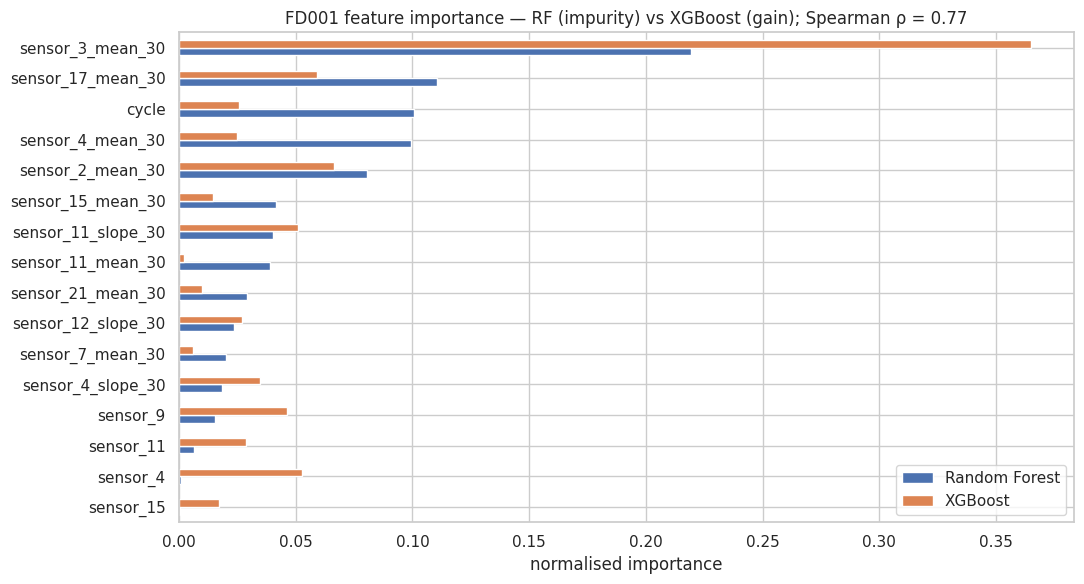

Importance share by feature type:


,Random Forest,XGBoost
current value,0.035,0.167
cycle,0.101,0.026
mean,0.676,0.571
slope,0.148,0.207
std,0.041,0.029


In [7]:
# Cell 7 — Compare feature importance
from scipy.stats import spearmanr

top_feats = list(dict.fromkeys(list(rf_imp.index[:12]) + list(xgb_imp.index[:12])))
imp_df = pd.DataFrame({"Random Forest": rf_imp, "XGBoost": xgb_imp}).loc[top_feats]
rho = spearmanr(rf_imp.reindex(NAMES), xgb_imp.reindex(NAMES)).correlation

fig, ax = plt.subplots(figsize=(11, 6))
imp_df.sort_values("Random Forest").plot.barh(ax=ax)
ax.set(title=f"FD001 feature importance — RF (impurity) vs XGBoost (gain); Spearman ρ = {rho:.2f}",
       xlabel="normalised importance")
fig.tight_layout(); fig.savefig(FIG_DIR / "14_rf_vs_xgb_importance.png", dpi=150, bbox_inches="tight"); plt.show()

kind = lambda n: "cycle" if n == "cycle" else ("slope" if "_slope_" in n else "std" if "_std_" in n
                                                else "mean" if "_mean_" in n else "current value")
by_kind = pd.DataFrame({"Random Forest": rf_imp.groupby(rf_imp.index.map(kind)).sum(),
                        "XGBoost": xgb_imp.groupby(xgb_imp.index.map(kind)).sum()}).round(3)
print("Importance share by feature type:"); display(by_kind)

**What to look for:** if the top features are mostly `*_mean_30` (smoothed sensors) and `*_slope_30` (degradation trend), the Phase 4 feature engineering is doing its job — the models prefer the denoised history over single noisy readings.

---
## Cell 8 — Model 4: LSTM (tuned architecture, early stopping)
**What it is:** a Long Short-Term Memory network reads the last **30 cycles × 14 sensors** one step at a time, keeping an internal memory that summarises the trend. We use the memory after the **last** step → small dense layer → predicted RUL.

**Training details:**
- Target scaled to `RUL / 125` (range 0–1) → stable gradients; predictions are multiplied back by 125.
- Loss: **MSE** (mean squared error) — the standard regression loss and directly linked to RMSE.
- Optimiser: Adam, learning rate 0.001, batch 256, gradient clipping at 1.0.
- **Early stopping:** after each epoch, compute the loss on the 16 tune engines; stop after 8 epochs without improvement and **restore the best weights** (best checkpoint).

**Architectures tried (4):** hidden size 64 or 128 × 1 or 2 LSTM layers (dropout 0.2 between layers).

The best architecture is then **re-trained on all 80 training engines** for its best number of epochs.

⏱️ On a T4 GPU this cell takes about 1–3 minutes; on Colab's CPU-only runtime it can take 10–15 minutes.

[1/4] {'hidden': 64, 'layers': 1, 'dropout': 0.0}
    epoch   1  train 0.2758  val 0.0399  (best epoch 1)
    epoch   5  train 0.0178  val 0.0192  (best epoch 5)
    epoch  10  train 0.0112  val 0.0143  (best epoch 8)
    epoch  15  train 0.0088  val 0.0155  (best epoch 11)
    early stop at epoch 19; best epoch 11
  → best epoch 11, tune RMSE≤125 13.95 (10s)
[2/4] {'hidden': 64, 'layers': 2, 'dropout': 0.2}
    epoch   1  train 0.2008  val 0.0283  (best epoch 1)
    epoch   5  train 0.0157  val 0.0227  (best epoch 3)
    epoch  10  train 0.0101  val 0.0217  (best epoch 7)
    epoch  15  train 0.0080  val 0.0168  (best epoch 7)
    early stop at epoch 15; best epoch 7
  → best epoch 7, tune RMSE≤125 15.24 (3s)
[3/4] {'hidden': 128, 'layers': 1, 'dropout': 0.0}
    epoch   1  train 0.1581  val 0.0280  (best epoch 1)
    epoch   5  train 0.0166  val 0.0178  (best epoch 5)
    epoch  10  train 0.0100  val 0.0173  (best epoch 9)
    epoch  15  train 0.0085  val 0.0126  (best epoch 9)
    e

,hidden,layers,dropout,best_epoch,tune_RMSE_le_cap,tune_NASA_le_cap,fit_s
0,128,2,0.2,5,13.861,432.507,6.879
1,64,1,0.0,11,13.954,413.292,10.436
2,128,1,0.0,9,14.994,582.153,3.135
3,64,2,0.2,7,15.243,499.115,2.960


Best LSTM config: {'hidden': 128, 'layers': 2, 'dropout': 0.2, 'best_epoch': 5}


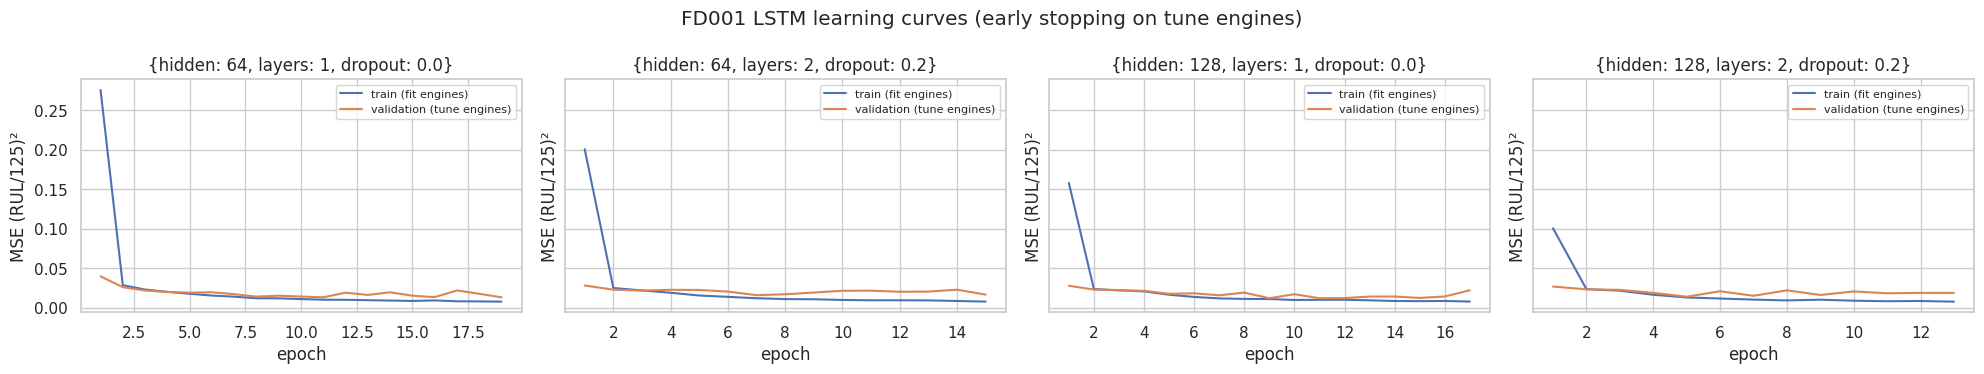

In [8]:
# Cell 8 — LSTM tuning
lstm_grid = [{"hidden": 64, "layers": 1, "dropout": 0.0}, {"hidden": 64, "layers": 2, "dropout": 0.2},
             {"hidden": 128, "layers": 1, "dropout": 0.0}, {"hidden": 128, "layers": 2, "dropout": 0.2}]
LSTM_TRAIN = dict(epochs=60, patience=8, lr=1e-3, batch_size=256, device=DEVICE, seed=SEED)

lstm_rows, histories, best = [], {}, (np.inf, None, None)
t0 = time.perf_counter()
for i, cfg in enumerate(lstm_grid, 1):
    print(f"[{i}/{len(lstm_grid)}] {cfg}")
    t1 = time.perf_counter()
    net, hist, best_epoch = mt.train_lstm(cfg, S_fit, s_fit, CAP, X_val=S_tune, y_val=s_tune, **LSTM_TRAIN)
    pred = mt.lstm_predict(net, S_tune_pts, CAP, DEVICE)
    m = mt.point_metrics(y_tune_true, pred, CAP)
    histories[str(cfg)] = hist
    lstm_rows.append({**cfg, "best_epoch": best_epoch, "tune_RMSE_le_cap": m["RMSE_le_cap"],
                      "tune_NASA_le_cap": m["NASA_le_cap"], "fit_s": time.perf_counter() - t1})
    print(f"  → best epoch {best_epoch}, tune RMSE≤125 {m['RMSE_le_cap']:.2f} ({lstm_rows[-1]['fit_s']:.0f}s)")
    if m["RMSE_le_cap"] < best[0]:
        best = (m["RMSE_le_cap"], {**cfg, "best_epoch": best_epoch}, net)
lstm_tuning_s = time.perf_counter() - t0

lstm_tuning = pd.DataFrame(lstm_rows).sort_values("tune_RMSE_le_cap").reset_index(drop=True)
lstm_tuning.to_csv(RESULT_DIR / "lstm_tuning.csv", index=False)
display(lstm_tuning.round(3))
lstm_best = best[1]
print("Best LSTM config:", lstm_best)

(MODEL_DIR / "lstm").mkdir(parents=True, exist_ok=True)
torch.save(best[2].state_dict(), MODEL_DIR / "lstm" / "tuning_best_checkpoint.pt")   # early-stopped checkpoint

fig, axes = plt.subplots(1, len(histories), figsize=(5 * len(histories), 3.8), sharey=True)
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h.epoch, h.train_loss, label="train (fit engines)")
    ax.plot(h.epoch, h.val_loss, label="validation (tune engines)")
    ax.set(title=name.replace("'", ""), xlabel="epoch", ylabel="MSE (RUL/125)²"); ax.legend(fontsize=8)
fig.suptitle("FD001 LSTM learning curves (early stopping on tune engines)")
fig.tight_layout(); fig.savefig(FIG_DIR / "15_lstm_learning_curves.png", dpi=150, bbox_inches="tight"); plt.show()

**Reading the learning curves:**
- Both curves falling together → the model is learning general patterns.
- Training loss keeps falling while validation loss flattens or rises → **overfitting** starts; early stopping picks the epoch with the lowest validation loss.
- Validation loss *below* training loss early on is normal here: dropout is active only during training, and the tune engines may simply be slightly easier.

## Cell 9 — Re-train the best LSTM on all 80 engines and save

In [9]:
# Cell 9 — Final LSTM on 80 engines for the selected number of epochs
arch = {k: lstm_best[k] for k in ("hidden", "layers", "dropout")}
final_epochs = int(lstm_best["best_epoch"])
t0 = time.perf_counter()
lstm, lstm_hist, _ = mt.train_lstm(arch, S_tr80, s_tr80, CAP, **{**LSTM_TRAIN, "epochs": final_epochs})
lstm_train_s = time.perf_counter() - t0

pred, lstm_inf_s = mt.time_inference(lambda: mt.lstm_predict(lstm, S_val_pts, CAP, DEVICE))
val_preds["LSTM"] = pred
results["LSTM"] = {**mt.point_metrics(y_val_true, pred, CAP),
                   "train_s": lstm_train_s, "tuning_s": lstm_tuning_s, "infer_ms_200": lstm_inf_s * 1000}

size = mt.save_model_bundle(MODEL_DIR / "lstm", lstm, "lstm", {
    "dataset": FD, "model": "LSTM", "input": "sequence", "seq_len": SEQ_LEN, "features": B,
    "n_features": len(B), "architecture": arch, "epochs": final_epochs,
    "training": {k: v for k, v in LSTM_TRAIN.items() if k != "device"}, "target_scaling": f"RUL / {CAP}",
    "rul_cap": CAP, "train_engines": len(train_ids), "train_time_s": lstm_train_s,
    "tuning_time_s": lstm_tuning_s, "validation_metrics": results["LSTM"]})

# Reload from disk and check identical predictions (what the API will do later)
reloaded, _ = mt.load_lstm(MODEL_DIR / "lstm", DEVICE)
assert np.allclose(mt.lstm_predict(reloaded, S_val_pts, CAP, DEVICE), pred, atol=1e-3)
r = results["LSTM"]
print(f"✅ LSTM saved + reload verified ({size:.2f} MB)")
print(f"Validation (200 pts): RMSE≤125 {r['RMSE_le_cap']:.2f} | MAE≤125 {r['MAE_le_cap']:.2f} | "
      f"bias {r['bias_le_cap']:+.1f} | RMSE all {r['RMSE_all']:.2f}")

    epoch   1  train 0.0874
    epoch   5  train 0.0119
✅ LSTM saved + reload verified (1.69 MB)
Validation (200 pts): RMSE≤125 15.95 | MAE≤125 11.68 | bias +3.9 | RMSE all 39.66


---
## Cell 10 — Validation comparison of the 4 models
Same 200 test-like points from the 20 validation engines for every model. Times:
- **Train time** = final fit on 80 engines (excludes tuning; tuning time shown separately).
- **Inference** = median time to predict all 200 points (features already computed).

Lower is better for every error metric. Bias: + = late (dangerous), − = early (conservative).

,MAE (≤125),RMSE (≤125),NASA (≤125),Bias (≤125),RMSE (all 200),Train time (s),Tuning time (s),Inference (ms / 200 pts)
Model,,,,,,,,
Linear Regression,16.62,20.26,1250.63,6.43,41.86,0.09,0.00,3.45
Random Forest,10.87,13.99,481.61,4.27,37.83,39.42,265.23,44.44
XGBoost,10.42,13.67,451.26,3.99,37.73,0.48,5.27,2.83
LSTM,11.68,15.95,1003.05,3.90,39.66,2.31,23.41,2.95


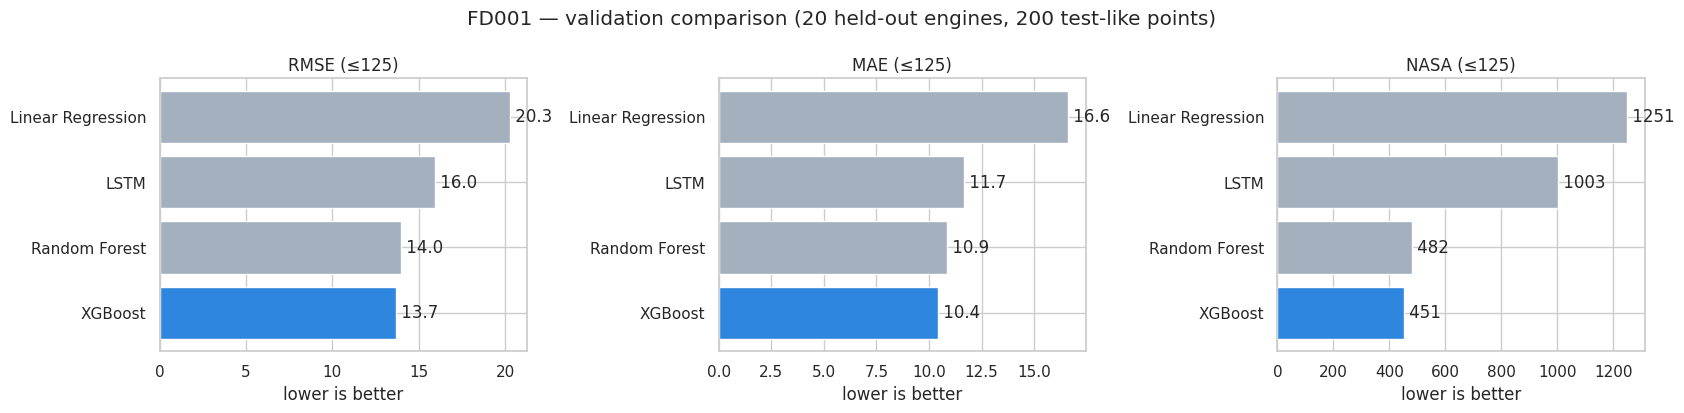

Current leader on the primary metric: XGBoost
Formal model selection, residual analysis and the official test-set evaluation happen in Phase 6.


In [10]:
# Cell 10 — Comparison table + chart
cols = {"MAE_le_cap": "MAE (≤125)", "RMSE_le_cap": "RMSE (≤125)", "NASA_le_cap": "NASA (≤125)",
        "bias_le_cap": "Bias (≤125)", "RMSE_all": "RMSE (all 200)", "train_s": "Train time (s)",
        "tuning_s": "Tuning time (s)", "infer_ms_200": "Inference (ms / 200 pts)"}
comparison = pd.DataFrame(results).T[list(cols)].rename(columns=cols)
comparison.index.name = "Model"
comparison.to_csv(RESULT_DIR / "validation_comparison.csv")
pd.DataFrame(val_preds).to_csv(RESULT_DIR / "validation_predictions.csv", index=False)
display(comparison.round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, col in zip(axes, ["RMSE (≤125)", "MAE (≤125)", "NASA (≤125)"]):
    s = comparison[col].sort_values()
    ax.barh(s.index, s.values, color=["#2E86DE" if i == 0 else "#A4B0BE" for i in range(len(s))])
    for y_, v in enumerate(s.values):
        ax.text(v, y_, f" {v:.1f}" if col != "NASA (≤125)" else f" {v:.0f}", va="center")
    ax.set(title=col, xlabel="lower is better")
fig.suptitle("FD001 — validation comparison (20 held-out engines, 200 test-like points)")
fig.tight_layout(); fig.savefig(FIG_DIR / "16_validation_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

leader = comparison["RMSE (≤125)"].idxmin()
print(f"Current leader on the primary metric: {leader}")
print("Formal model selection, residual analysis and the official test-set evaluation happen in Phase 6.")

## Cell 11 — What was saved
Every model folder contains the model file + `metadata.json` (hyperparameters, feature order, cap, training time, validation metrics), and points back to the shared `preprocessing/` and `feature_config.json` — so no model exists without its preprocessing.

In [11]:
# Cell 11 — Artifact inventory
for sub in ["preprocessing", "linear_regression", "random_forest", "xgboost", "lstm"]:
    folder = MODEL_DIR / sub
    files = sorted(folder.iterdir())
    print(f"{sub + '/':20s}", ", ".join(f"{f.name} ({f.stat().st_size / 1e6:.2f} MB)" for f in files))
print("\nResults:", sorted(p.name for p in RESULT_DIR.iterdir()))

preprocessing/       pipeline_metadata.json (0.00 MB), preprocessing_config.json (0.00 MB), scaler.joblib (0.00 MB)
linear_regression/   metadata.json (0.00 MB), model.joblib (0.00 MB)
random_forest/       metadata.json (0.00 MB), model.joblib (11.57 MB)
xgboost/             metadata.json (0.00 MB), model.json (0.63 MB)
lstm/                metadata.json (0.00 MB), model.pt (0.84 MB), tuning_best_checkpoint.pt (0.84 MB)

Results: ['lstm_tuning.csv', 'rf_feature_importance.csv', 'rf_tuning.csv', 'validation_comparison.csv', 'validation_predictions.csv', 'xgb_feature_importance.csv', 'xgb_tuning.csv']
